# Urban Mobility and Economic Productivity
TripleTen academic case study by Andres Murcia.

This portfolio version contains the analysis code, saved plots and English executive summary. Re-running the notebook requires the original TomTom Traffic Index and OECD Cities CSV files from the course environment.

# Executive Summary

## Context and Objective

The bank wants to identify cities where investment in transport could improve productivity and quality of life. This analysis examines how city traffic indicators, including congestion, travel times and delays, relate to economic indicators such as GDP per capita and unemployment. The data comes from two sources: the TomTom Traffic Index for traffic measures and OECD Cities for economic and population information.

## Data Coverage

The analysis covers 2024 and includes 15 cities across seven countries: Argentina, Brazil, Chile, Colombia, Mexico, Peru and Uruguay.

## Methodology

First, the data was cleaned by standardizing column names and correcting dates and numbers supplied in different formats. Traffic measures were then averaged by city and year. The two datasets were combined using an inner join, retaining only cities and years present in both. Three charts were used to review the results: a boxplot, a histogram and a bar chart comparing congestion and GDP per capita by city.

## Findings

There is no clear visible relationship between GDP per capita and congestion. Mexico City has the highest congestion despite its high GDP per capita, while Montevideo and Brasilia have high GDP per capita and almost no congestion. Lima and Bogota have substantial congestion and lower GDP per capita than other large cities. Most cities have low congestion, while a few have very high values, placing the mean above the median. Santiago's GDP per capita also stands out as much lower than that of the other cities.

## Recommendations

Lima and Bogotá warrant further investigation because they combine substantial congestion with lower GDP per capita than some other major cities. Before making decisions, Santiago's GDP figure should be verified. Since the analysis includes only 15 cities, additional information, such as population and public transport, should be incorporated to provide a more complete picture.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

In [3]:
# mostrar las primeras 5 filas de traffic
traffic.head()

In [4]:
# mostrar las primeras 5 filas de eco
eco.head()

In [5]:
# Examinar la estructura de traffic
traffic.info()
traffic.head(3)

In [6]:
# Examinar la estructura de eco
eco.info()
eco.head(3)

In [7]:
# Estandarizar los nombres de las columnas de traffic
#tu código aquí
traffic = traffic.rename(columns={
    'Country': 'country',
    'City': 'city',
    'UpdateTimeUTC': 'update_time_utc',
    'JamsDelay': 'jams_delay',
    'TrafficIndexLive': 'traffic_index_live',
    'JamsLengthInKms': 'jams_length_kms',
    'JamsCount': 'jams_count',
    'TrafficIndexWeekAgo': 'traffic_index_week_ago',
    'UpdateTimeUTCWeekAgo': 'update_time_utc_week_ago',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins',
    'TravelTimeHistoricPer10KmsMins': 'travel_time_hist_per_10kms_mins',
    'MinsDelay': 'mins_delay'
})
# verificar cambios
traffic.columns

In [8]:
# Estandarizar los nombres de las columnas de eco
#tu código aquí
eco = eco.rename(columns={
    'Year': 'year',
    'City': 'city',
    'Country': 'country',
    'City GDP/capita': 'city_gdp_capita',
    'Unemployment %': 'unemployment_pct',
    'PM2.5 (μg/m³)': 'pm25',
    'Population (M)': 'population_m'
})
# verificar cambios
eco.columns

In [9]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='coerce')

# verificar el cambio
traffic.info()


In [10]:
# Limpia separadores y convierte columnas numéricas en eco
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False).astype(float)
eco['unemployment_pct'] = eco['unemployment_pct'].astype(str).str.replace('%', '', regex=False).str.replace(',', '.', regex=False).astype(float)
eco['population_m'] = eco['population_m'].astype(str).str.replace(',', '.', regex=False).astype(float)

# Calcula la población total en unidades absolutas (Multiplica * 1000000)
eco['population'] = eco['population_m'] * 1000000

# verificar el cambio
eco.info()
eco.head(3)

In [11]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar cambio
traffic.head(3)

In [12]:
# Filtra los registros del año 2024
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


In [17]:
# Calcular los  promedios de trafico por ciudad, país y año  
traffic_city_year_2024 =(traffic_2024.groupby(['city', 'country', 'year'], as_index=False)[[
        'jams_delay',
        'traffic_index_live',
        'jams_length_kms',
        'jams_count',
        'mins_delay',
        'travel_time_live_per_10kms_mins',
        'travel_time_hist_per_10kms_mins'
    ]]
    .mean()
)
# Mostrar resultado
traffic_city_year_2024.head()

In [18]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

In [19]:

# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets
merged = pd.merge(traffic_2024_small, eco_2024_small, on=['city', 'year'], how='inner')

# Mostrar las primeras 5 filas
merged.head()


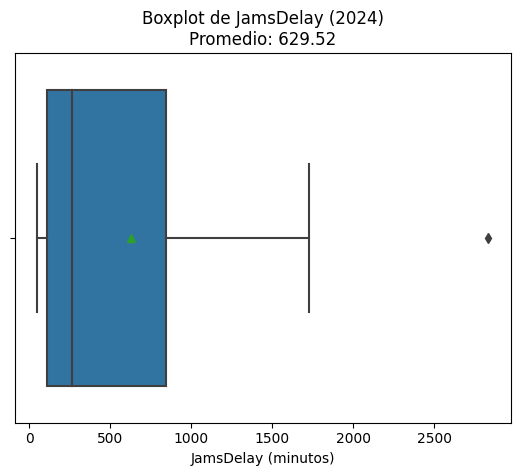

In [20]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
sns.boxplot(x=merged['jams_delay'], showmeans=True)
plt.xlabel('JamsDelay (minutos)')

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


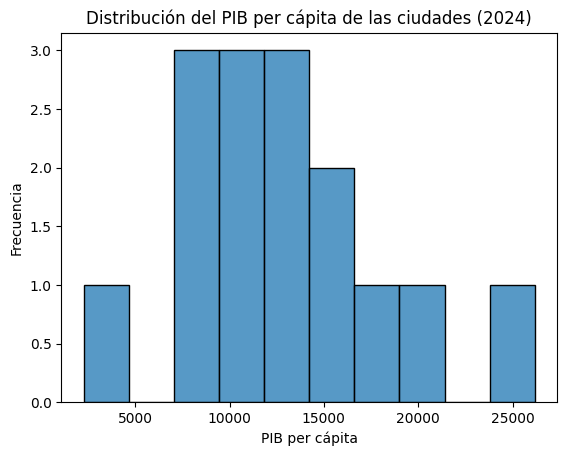

In [21]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
sns.histplot(data=merged, x='city_gdp_capita', bins=10)
plt.title('Distribución del PIB per cápita de las ciudades (2024)')
plt.xlabel('PIB per cápita')
plt.ylabel('Frecuencia')
plt.show()


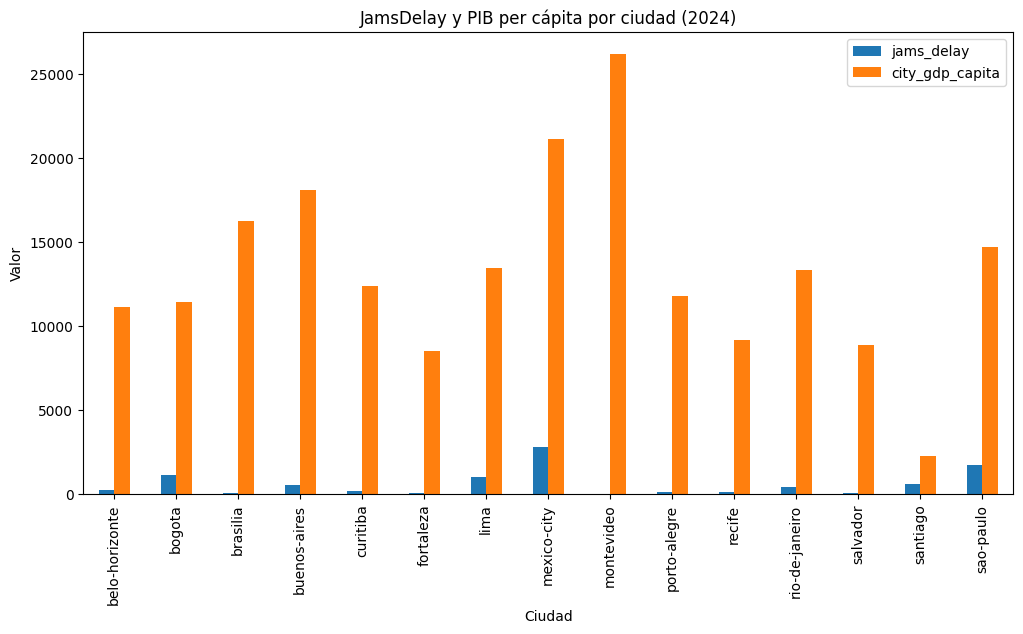

In [22]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
merged.plot(kind='bar', x='city', y=['jams_delay', 'city_gdp_capita'], figsize=(12, 6))

plt.title('JamsDelay y PIB per cápita por ciudad (2024)')
plt.xlabel('Ciudad')
plt.ylabel('Valor')
plt.xticks(rotation=90)
plt.show()

In [23]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)